In [1]:
import eurostat
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
class EuroStatExplorer:
    """Explore, retrieve, and visualize Eurostat data."""

    def __init__(self):
        """Load the Eurostat dataset catalogue."""
        self.toc_df = eurostat.get_toc_df()
        self.raw_data = None

    def search_dataset(self, keyword):
        """Search for datasets matching a keyword."""
        return eurostat.subset_toc_df(self.toc_df, keyword)

    def get_parameters(self, dataset_code):
        """Retrieve the dimensions of a dataset."""
        return eurostat.get_pars(dataset_code)

    def load_dataset(self, dataset_code):
        """Retrieve a dataset from Eurostat."""
        self.raw_data = eurostat.get_data_df(dataset_code)
        return self.raw_data

    def inspect_dataset(self):
        """Display basic information about loaded data."""
        if self.raw_data is None:
            raise ValueError("Load a dataset before inspecting it.")

        print("Shape:", self.raw_data.shape)
        print("Columns:", self.raw_data.columns.tolist())
        print("Data types:")
        print(self.raw_data.dtypes)
        print("First observations:")
        print(self.raw_data.head())

    def plot_line(self, data, title, xlabel, ylabel):
        """Create a line chart from a prepared DataFrame."""
        ax = data.plot(kind="line", marker="o", figsize=(10, 5))
        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        plt.tight_layout()
        plt.show()

    def plot_bar(self, data, x, y, title, xlabel, ylabel):
        """Create a bar chart from a prepared DataFrame."""
        plt.figure(figsize=(10, 5))
        sns.barplot(data=data, x=x, y=y)
        plt.title(title)
        plt.xlabel(xlabel)
        plt.ylabel(ylabel)
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

    def plot_scatter(self, data, x, y, title, xlabel, ylabel):
        """Create a scatterplot from a prepared DataFrame."""
        plt.figure(figsize=(8, 5))
        sns.scatterplot(data=data, x=x, y=y)
        plt.title(title)
        plt.xlabel(xlabel)
        plt.ylabel(ylabel)
        plt.tight_layout()
        plt.show()

    def plot_histogram(self, data, column, title, xlabel):
        """Create a histogram of a numerical variable."""
        values = pd.to_numeric(data[column], errors="coerce").dropna()
        plt.figure(figsize=(8, 5))
        sns.histplot(values, bins=15, kde=True)
        plt.title(title)
        plt.xlabel(xlabel)
        plt.ylabel("Frequency")
        plt.tight_layout()
        plt.show()

In [3]:
es = EuroStatExplorer()

In [4]:
es.get_parameters("mar_mg_aa_cwh")
dataset1 =es.load_dataset("mar_mg_aa_cwh")
es.inspect_dataset()

Shape: (99, 31)
Columns: ['freq', 'unit', 'rep_mar\\TIME_PERIOD', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024']
Data types:
freq                       str
unit                       str
rep_mar\TIME_PERIOD        str
1997                   float64
1998                   float64
1999                   float64
2000                   float64
2001                   float64
2002                   float64
2003                   float64
2004                   float64
2005                   float64
2006                   float64
2007                   float64
2008                   float64
2009                   float64
2010                   float64
2011                   float64
2012                   float64
2013                   float64
2014                   float64
2015                   float64
2016            

In [5]:
transposed_dataset1 = dataset1.T

dataset1_pop = transposed_dataset1
dataset1_df = transposed_dataset1.iloc[20:31].copy()
dataset1_df.columns = transposed_dataset1.iloc[2].tolist()
print(dataset1_df)

       BE    BG    CY   DE   DK    EE EEA31   EL   ES EU15  ...    MT    NL  \
2014  4.3  -5.6   0.2  2.2  4.3   1.6   1.6  4.7  7.6  1.8  ...   8.0  33.9   
2015  1.5  -0.3  42.9 -2.6  3.1 -19.8   0.9 -0.9  4.5  1.4  ...   8.3  34.7   
2016  5.0   5.6  -0.1  0.4  0.8  -3.9   0.6  4.8  0.9  0.5  ...   8.3  34.1   
2017  1.7   7.9 -23.4  0.7 -1.2   3.6   2.8  3.5  7.2  2.6  ...   8.8  34.6   
2018  4.8 -10.0 -11.6 -1.0  1.4   3.3   2.7  5.1  2.9  2.4  ...   9.4  34.8   
2019  2.8  11.2   6.9 -0.6 -2.4   5.0   0.0  2.1 -0.2  0.0  ...  10.3  34.8   
2020 -3.3 -18.5   0.6 -6.4 -2.5   0.0   NaN -8.3 -8.3  NaN  ...  11.1  31.4   
2021  7.5   1.3  -6.5  4.9  3.1   4.5   NaN -0.1  4.7  NaN  ...   6.5  33.1   
2022 -0.2  20.2  17.9 -3.4  4.2 -15.5   NaN -4.2  2.7  NaN  ...   9.2  33.3   
2023 -5.3  -2.4   6.2 -4.1 -4.9 -31.0   NaN  0.7 -3.7  NaN  ...  13.0  30.5   
2024  0.7  -1.5   2.3  2.3  0.4  -5.6   NaN  0.7  3.0  NaN  ...   7.9  29.9   

        NO   PL   PT   RO    SE    SI   TR   UK  
2

In [6]:
countries = ["PT", "NL", "IT"]

dataset1_filtered = dataset1_df[countries]
print(dataset1_filtered)
mask = dataset1_df.columns.str[:2].isin(countries)
dataset1_ports = dataset1_df.loc["2014":"2024", mask]
print(dataset1_ports)

       PT       PT   PT   NL        NL    NL   IT        IT   IT
2014  2.4  80156.0  7.7  2.3  571636.0  33.9 -3.0  443141.0  7.3
2015  8.2  86769.0  8.4  3.0  588506.0  34.7  3.4  458020.0  7.5
2016  5.3  91344.0  8.8 -1.3  581070.0  34.1  0.9  461990.0  7.6
2017  2.2  93356.0  9.1  2.1  593489.0  34.6  2.9  475164.0  7.8
2018 -3.2  90361.0  8.8  1.1  599843.0  34.8  5.6  501958.0  8.3
2019 -5.6  85320.0  8.2  0.5  602821.0  34.8  1.2  508074.0  8.5
2020 -7.0  79371.0  7.7 -9.1  547758.0  31.4 -7.6  469635.0  7.9
2021  4.7  83080.0  8.0  5.9  580179.0  33.1  6.8  501603.0  8.5
2022  2.3  85025.0  8.2  1.7  589935.0  33.3  1.6  509397.0  8.6
2023 -3.4  82110.0  7.8 -7.6  545105.0  30.5 -4.0  488888.0  8.3
2024  4.3  85669.0  8.0 -1.3  538120.0  29.9 -0.1  488556.0  8.3
       IT   NL   PT        IT        NL       PT   IT    NL   PT
2014 -3.0  2.3  2.4  443141.0  571636.0  80156.0  7.3  33.9  7.7
2015  3.4  3.0  8.2  458020.0  588506.0  86769.0  7.5  34.7  8.4
2016  0.9 -1.3  5.3  4619

In [7]:
#Here is the weight from goods in thowsand tonnes as a unit from the dataset mar_mg_aa_cwh
units = transposed_dataset1.loc["unit"].to_numpy()          
thousandTonnes = (units == "THS_T") & dataset1_df.columns.isin(countries)

dataset1_thousandTonnes = dataset1_df.loc["2014":"2024", thousandTonnes].apply(pd.to_numeric)
print(dataset1_thousandTonnes)


            IT        NL       PT
2014  443141.0  571636.0  80156.0
2015  458020.0  588506.0  86769.0
2016  461990.0  581070.0  91344.0
2017  475164.0  593489.0  93356.0
2018  501958.0  599843.0  90361.0
2019  508074.0  602821.0  85320.0
2020  469635.0  547758.0  79371.0
2021  501603.0  580179.0  83080.0
2022  509397.0  589935.0  85025.0
2023  488888.0  545105.0  82110.0
2024  488556.0  538120.0  85669.0


In [8]:
#Here is the weight from goods in tonnes per capita as a unit from the dataset mar_mg_aa_cwh

units = transposed_dataset1.loc["unit"].to_numpy()          
tonnesPerCapita = (units == "T_HAB") & dataset1_df.columns.isin(countries)

dataset1_tonnesPerCapita = dataset1_df.loc["2014":"2024", tonnesPerCapita].apply(pd.to_numeric)
print(dataset1_tonnesPerCapita)

       IT    NL   PT
2014  7.3  33.9  7.7
2015  7.5  34.7  8.4
2016  7.6  34.1  8.8
2017  7.8  34.6  9.1
2018  8.3  34.8  8.8
2019  8.5  34.8  8.2
2020  7.9  31.4  7.7
2021  8.5  33.1  8.0
2022  8.6  33.3  8.2
2023  8.3  30.5  7.8
2024  8.3  29.9  8.0


In [9]:
#Here is the weight from goods in growth rate based from the year before
#as a unit from the dataset mar_mg_aa_cwh

units = transposed_dataset1.loc["unit"].to_numpy()         
growthRate = (units == "RT_PRE") & dataset1_df.columns.isin(countries)

dataset1_growthRate = dataset1_df.loc["2014":"2024", growthRate].apply(pd.to_numeric)
print(dataset1_growthRate)

       IT   NL   PT
2014 -3.0  2.3  2.4
2015  3.4  3.0  8.2
2016  0.9 -1.3  5.3
2017  2.9  2.1  2.2
2018  5.6  1.1 -3.2
2019  1.2  0.5 -5.6
2020 -7.6 -9.1 -7.0
2021  6.8  5.9  4.7
2022  1.6  1.7  2.3
2023 -4.0 -7.6 -3.4
2024 -0.1 -1.3  4.3


In [10]:
NAMES = {"PT": "Portugal", "IT": "Italy", "NL": "Netherlands"}

THEME = "Ocean"   # choose: "Ocean", "Forest", "Sunset"
themes = {"Ocean": ["#6696b3", "#d2a071", "#69a89d"],
          "Forest": ["#75957a", "#b3b97b", "#bc957d"],
          "Sunset": ["#b27d91", "#daa47d", "#909cbd"]}
palette = themes[THEME]
color_map = dict(zip(countries, palette))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

def prep(df):
    """Years as numbers (2014…2024) and the countries always in the same order."""
    t = df.copy()
    t.index = t.index.astype(int)
    t.index.name = "year"
    return t[countries]

tonnes = prep(dataset1_thousandTonnes)    # THS_T: thousand tonnes
per_cap = prep(dataset1_tonnesPerCapita)  # T_HAB: tonnes per capita
growth = prep(dataset1_growthRate)        # RT_PRE: growth rate on previous year, %

def eu_series(unit):
    """EU27 benchmark for one unit (None if the dataset has no EU27_2020 column)."""
    cols = (units == unit) & (dataset1_df.columns == "EU27_2020")
    if not cols.any():
        return None
    s = dataset1_df.loc["2014":"2024", cols].apply(pd.to_numeric).iloc[:, 0]
    s.index = s.index.astype(int)
    return s

eu = eu_series("THS_T")
eu_per_cap = eu_series("T_HAB")

long = growth.reset_index().melt(id_vars="year", var_name="country", value_name="growth")

check = (tonnes.pct_change(fill_method=None) * 100).round(1) - growth
print("Largest difference between RT_PRE and our own calculation (2015–2024):",
      check.loc[2015:].abs().max().round(1).to_dict())

Largest difference between RT_PRE and our own calculation (2015–2024): {'PT': 0.1, 'NL': 0.0, 'IT': 0.0}


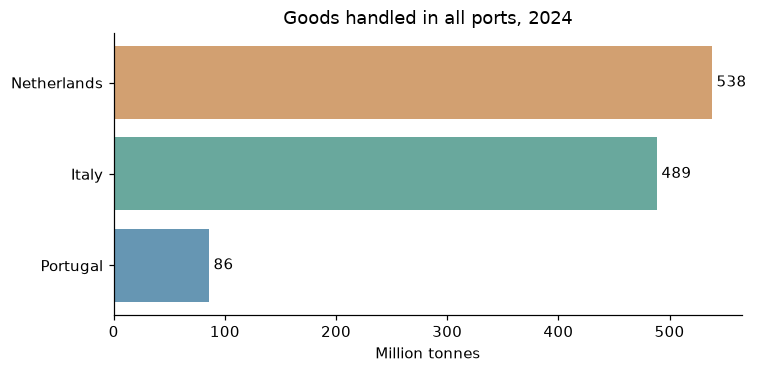

                 2014      2019      2024  peak year      peak  low year       low  change 2014–2024 (%)  CAGR 2014–2024 (%)
Portugal      80156.0   85320.0   85669.0       2017   93356.0      2020   79371.0                   6.9                 0.7
Netherlands  571636.0  602821.0  538120.0       2019  602821.0      2024  538120.0                  -5.9                -0.6
Italy        443141.0  508074.0  488556.0       2022  509397.0      2014  443141.0                  10.2                 1.0


In [11]:
#THS_T 2. Size ranking: sorted horizontal bars and summary table
YEAR = 2024
values = (tonnes.loc[YEAR] / 1000).sort_values()          # million tonnes, smallest first

fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh([NAMES[c] for c in values.index], values.values, color=[color_map[c] for c in values.index])
ax.bar_label(bars, fmt="%.0f", padding=3)
ax.set(title=f"Goods handled in all ports, {YEAR}", xlabel="Million tonnes")
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    "2014": tonnes.loc[2014], "2019": tonnes.loc[2019], "2024": tonnes.loc[2024],
    "peak year": tonnes.idxmax(), "peak": tonnes.max(),
    "low year": tonnes.idxmin(), "low": tonnes.min(),
    "change 2014–2024 (%)": (tonnes.loc[2024] / tonnes.loc[2014] - 1) * 100,
    "CAGR 2014–2024 (%)": ((tonnes.loc[2024] / tonnes.loc[2014]) ** (1 / 10) - 1) * 100,
}).round(1).rename(index=NAMES)
print(summary)

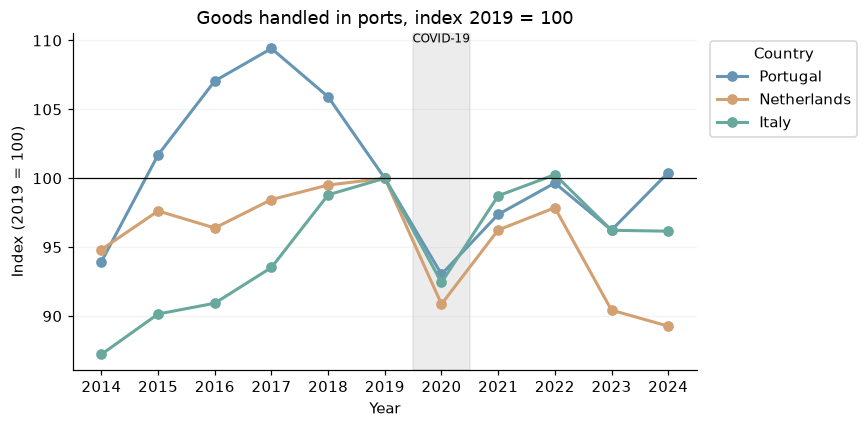

Back to the 2019 level in: {'Portugal': 2024, 'Netherlands': 'not by 2024', 'Italy': 2022}
         PT     NL     IT
year                     
2014   93.9   94.8   87.2
2015  101.7   97.6   90.1
2016  107.1   96.4   90.9
2017  109.4   98.5   93.5
2018  105.9   99.5   98.8
2019  100.0  100.0  100.0
2020   93.0   90.9   92.4
2021   97.4   96.2   98.7
2022   99.7   97.9  100.3
2023   96.2   90.4   96.2
2024  100.4   89.3   96.2


In [14]:
#Portugal's line would look flat next to Italy and the Netherlands
BASE_YEAR = 2019
index = tonnes / tonnes.loc[BASE_YEAR] * 100

fig, ax = plt.subplots(figsize=(8, 4))
for c in countries:
    ax.plot(index.index, index[c], marker="o", linewidth=2, color=color_map[c], label=NAMES[c])
ax.axhline(100, color="black", linewidth=0.8)
ax.axvspan(2019.5, 2020.5, color="grey", alpha=0.15)
ax.text(2020, ax.get_ylim()[1], "COVID-19", ha="center", va="top", fontsize=8)
ax.set(title=f"Goods handled in ports, index {BASE_YEAR} = 100", xlabel="Year", ylabel=f"Index ({BASE_YEAR} = 100)")
ax.set_xticks(index.index)
ax.grid(axis="y", alpha=0.15)
ax.legend(title="Country", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Recovery: first year after 2020 back at or above the 2019 level
recovery = {NAMES[c]: next((y for y in tonnes.index if y > 2020 and tonnes.loc[y, c] >= tonnes.loc[2019, c]),
                           "not by 2024") for c in countries}
print("Back to the 2019 level in:", recovery)
print(index.round(1))

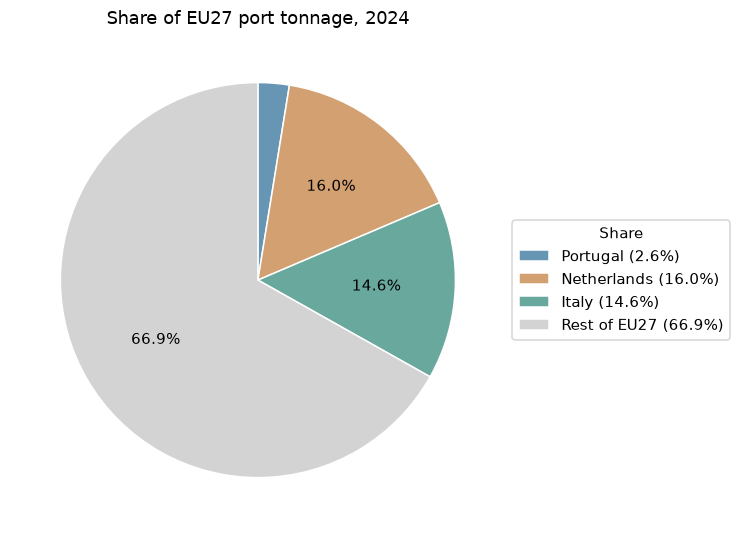

      Portugal  Netherlands  Italy
year                              
2014       2.4         17.4   13.5
2015       2.6         17.6   13.7
2016       2.7         17.2   13.7
2017       2.7         17.1   13.7
2018       2.5         16.8   14.0
2019       2.4         16.8   14.2
2020       2.4         16.5   14.2
2021       2.4         16.8   14.5
2022       2.4         16.8   14.5
2023       2.4         16.2   14.5
2024       2.6         16.0   14.6


In [19]:
#a pie only works for parts of a whole: the three countries + the rest of the EU27
YEAR = 2024
if eu is None:
    print("No EU27_2020 column in dataset1: this chart needs it.")
else:
    parts = tonnes.loc[YEAR].rename(NAMES)
    values = pd.concat([parts, pd.Series({"Rest of EU27": eu.loc[YEAR] - parts.sum()})])
    pct = values / values.sum() * 100
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.pie(values, colors=palette + ["lightgray"], startangle=90, counterclock=False,
           autopct=lambda p: f"{p:.1f}%" if p >= 3 else "", wedgeprops={"edgecolor": "white"})
    ax.legend([f"{n} ({v:.1f}%)" for n, v in pct.items()], title="Share", loc="center left", bbox_to_anchor=(1, 0.5))
    ax.set_title(f"Share of EU27 port tonnage, {YEAR}")
    plt.tight_layout()
    plt.show()
    print((tonnes.div(eu, axis=0) * 100).rename(columns=NAMES).round(1))

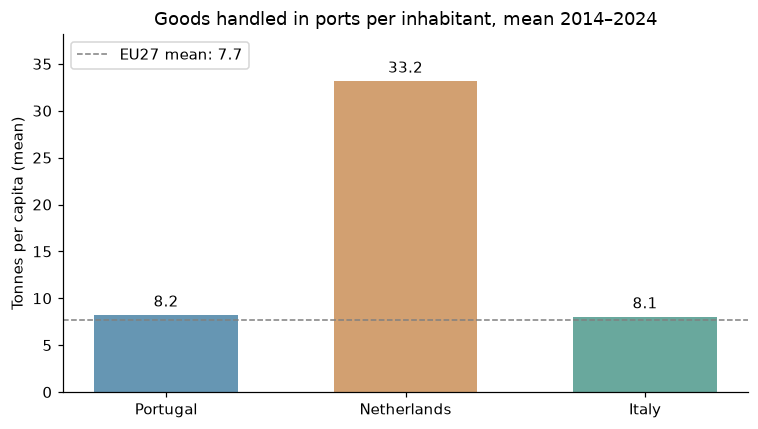

        Portugal  Netherlands  Italy
mean         8.2         33.2    8.1
median       8.2         33.9    8.3
std          0.5          1.8    0.5
min          7.7         29.9    7.3
max          9.1         34.8    8.6


In [21]:
#bars compare categories and start at zero
STAT = "mean"   # choose: "mean", "median"
values = per_cap.agg(STAT).rename(NAMES)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(values.index, values.values, color=palette, width=0.6)
ax.bar_label(bars, fmt="%.1f", padding=3)
if eu_per_cap is not None:
    eu_value = eu_per_cap.agg(STAT)
    ax.axhline(eu_value, color="grey", linestyle="--", linewidth=1, label=f"EU27 {STAT}: {eu_value:.1f}")
    ax.legend(loc="upper left")
ax.set(title=f"Goods handled in ports per inhabitant, {STAT} 2014–2024",
       ylabel=f"Tonnes per capita ({STAT})", ylim=(0, values.max() * 1.15))
plt.tight_layout()
plt.show()
print(per_cap.agg(["mean", "median", "std", "min", "max"]).rename(columns=NAMES).round(1))

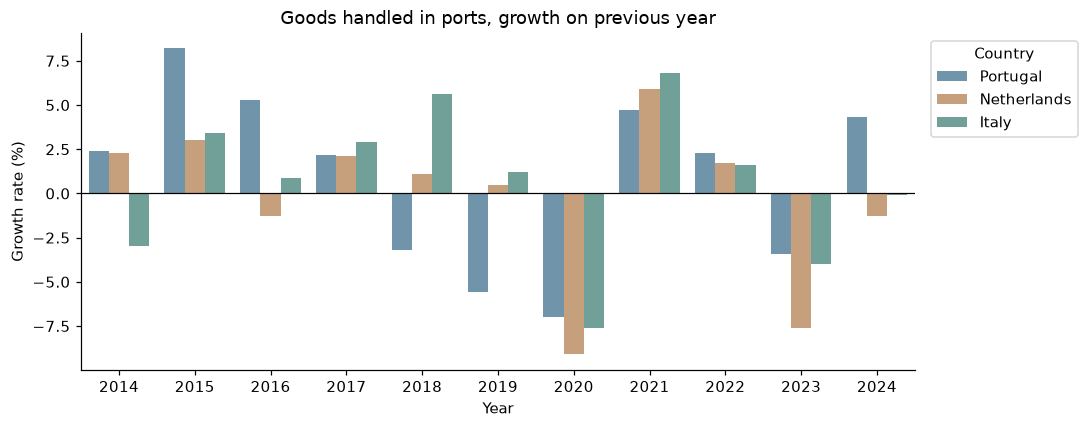

In [22]:
#makes the colour carry the country; the zero line separates rises from falls
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=long, x="year", y="growth", hue="country", hue_order=countries, palette=color_map, ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Goods handled in ports, growth on previous year", xlabel="Year", ylabel="Growth rate (%)")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, [NAMES[l] for l in labels], title="Country", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

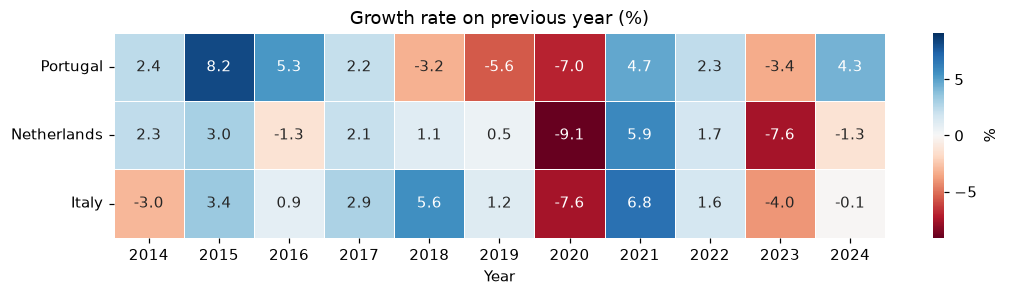

In [23]:
#red = fall, blue = rise; the scale is symmetric around zero
lim = np.nanmax(np.abs(growth.to_numpy()))
fig, ax = plt.subplots(figsize=(10, 2.8))
sns.heatmap(growth.T.rename(index=NAMES), annot=True, fmt=".1f", cmap="RdBu", center=0,
            vmin=-lim, vmax=lim, linewidths=0.5, cbar_kws={"label": "%"}, ax=ax)
ax.set(title="Growth rate on previous year (%)", xlabel="Year", ylabel="")
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()